# 06 — Linear Regression
## Goal
Build the first real regression model using a complete scikit-learn Pipeline.

The pipeline prevents a common mistake: fitting preprocessing on the whole dataset before the train/test split.

### Pipeline
`Missing-value imputation → One-hot encoding → Standardization → Linear Regression`

Scaling is not mathematically required for ordinary Linear Regression predictions, but we use it here because it makes the feature space comparable and gives us a consistent foundation for regularized models later.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../outputs/cleaned/zomato_model_dataset.csv")

target = "Time_taken (min)"
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_pipeline.fit(X_train, y_train)
pred = linear_pipeline.predict(X_test)

metrics = pd.DataFrame([{
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_test, pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    "R2": r2_score(y_test, pred)
}])

metrics.round(3)

,Model,MAE,RMSE,R2
0,Linear Regression,4.817,6.059,0.584


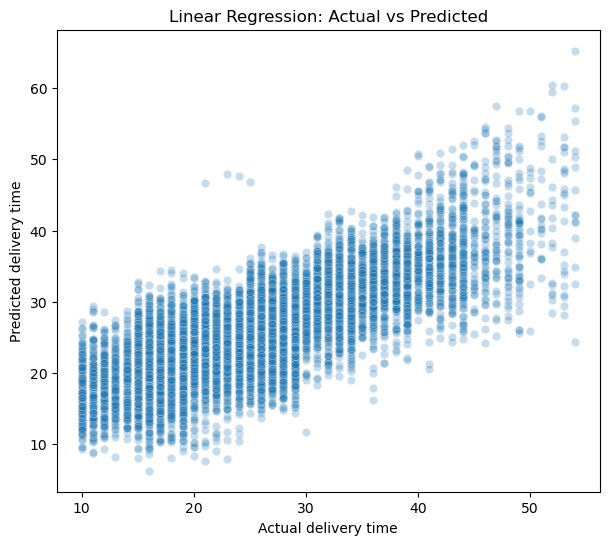

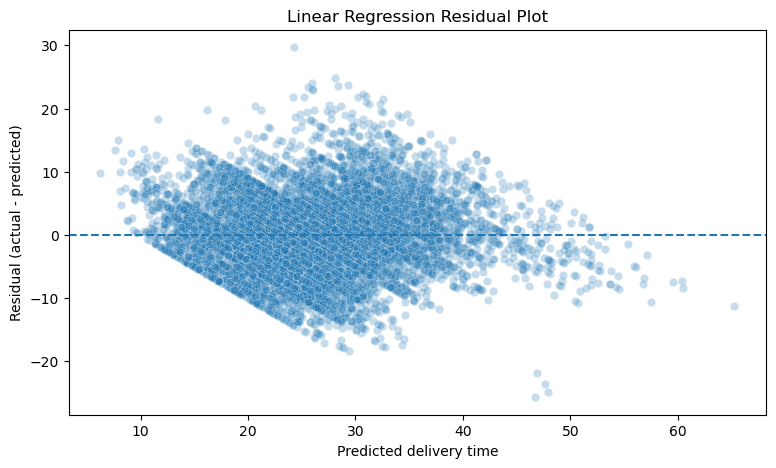

In [2]:
# Actual vs predicted
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=pred, alpha=0.25)
plt.xlabel("Actual delivery time")
plt.ylabel("Predicted delivery time")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

# Residuals
residuals = y_test - pred

plt.figure(figsize=(9, 5))
sns.scatterplot(x=pred, y=residuals, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted delivery time")
plt.ylabel("Residual (actual - predicted)")
plt.title("Linear Regression Residual Plot")
plt.show()

In [3]:
# Inspect learned coefficients.
feature_names = linear_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = linear_pipeline.named_steps["model"].coef_

coef_table = (
    pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
    .assign(abs_coefficient=lambda d: d["coefficient"].abs())
    .sort_values("abs_coefficient", ascending=False)
)

coef_table.head(20)

,feature,coefficient,abs_coefficient
30,cat__City_Semi-Urban,7.556058,7.556058
27,cat__Festival_No,-4.982266,4.982266
28,cat__Festival_Yes,4.982266,4.982266
31,cat__City_Urban,-4.773729,4.773729
17,cat__Road_traffic_density_Low,-4.435352,4.435352
13,cat__Weather_conditions_Sunny,-3.823969,3.823969
29,cat__City_Metropolitian,-2.782329,2.782329
16,cat__Road_traffic_density_Jam,2.640875,2.640875
15,cat__Road_traffic_density_High,2.640168,2.640168
10,cat__Weather_conditions_Fog,2.536404,2.536404


## What is optimization here?

Ordinary Linear Regression finds coefficients that minimize the **sum of squared residuals**.

A residual is:

`actual value − predicted value`

Squaring makes large errors more expensive and removes the sign.

The model therefore searches for coefficients that give the smallest total squared error on the training data.

This is the **least-squares optimization objective**.

Next we add regularization, which changes the objective by adding a penalty for large coefficients.